# Факторы деградации жилого фонда в РФ: предсказание аварийности многоквартирных домов методами машинного обучения
Исследовательский вопрос: Насколько точно алгоритмы машинного обучения способны предсказывать официальный статус аварийности многоквартирного дома, и каков относительный вклад институциональных (тип управления, регион) и инфраструктурных (возраст, площадь, материал) предикторов в эту вероятность?


## Данные
Датасет взят с сайта [Если быть точным](https://tochno.st/datasets/gisgkh).

**Что в данных**: износ и аварийность жилых домов

Данные об исправности и аварийности многоквартирных жилых домов  (МКД) России, внесенных в базу данных Государственной информационной системы жилищно-коммунального хозяйства (ГИС ЖКХ). В текущей версии набора данных сведения актуальны по состоянию на ноябрь 2025 года.

1. Институциональные и пространственные предикторы:
- **region_name** и **municipality_name** (Регион и Муниципалитет) — отражают уровень бюджетной обеспеченности и пространственное неравенство.
- **house_manegement_type** (Способ управления) — ключевая переменная, отражающая способность собственников к преодолению проблемы коллективного действия (ТСЖ, частная УК, непосредственное управление).
- **is_dormitory** (Статус общежития) — сконструированный бинарный признак (на основе атрибутов regional_property и municipal_property). Выделяет объекты с максимальным уровнем отчуждения проживающих от управления общим имуществом.
2. Инфраструктурные и архитектурные предикторы:
- **building_year** (Год постройки) и **plan_series** (Серия проекта здания) — базовые метрики объективного физического старения материалов и особенностей индустриального домостроения разных эпох.
- **total_area** и **residental_premises_area** (Общая и жилая площадь) — отражают масштаб объекта.
- **is_reconstructed** (Факт проведения реконструкции) — бинарный признак, созданный на основе наличия записи в поле reconstruction_year, указывающий на капитальные вложения в инфраструктуру здания.
- **internal_walls_type** и **house_type** — инженерно-конструктивные характеристики.
3. Целевая переменная (Target):
- На основе атрибута condition (Состояние здания) сформирована бинарная целевая переменная target. Домам со статусом «Аварийный» и «Ветхий» присвоен класс 1 (проблемный фонд), домам со статусом «Исправный» — класс 0.


In [ ]:
! pip install catboost

In [ ]:
! unzip data_gisgkh_157_v20251205_csv.zip

Archive:  data_gisgkh_157_v20251205_csv.zip
replace description_gisgkh_157_v20251204.pdf? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace __MACOSX/._description_gisgkh_157_v20251204.pdf? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace data_gisgkh_157_v20251205.parquet? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace __MACOSX/._data_gisgkh_157_v20251205.parquet? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace data_gisgkh_157_v20251205.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace __MACOSX/._data_gisgkh_157_v20251205.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: no


In [ ]:
import pandas as pd

df = pd.read_csv("data_gisgkh_157_v20251205.csv", sep=';', encoding='utf-8')
df

,full_address,region_name,region_oktmo,region_okato,municipality_name,municipality_oktmo,address_id,deterioration,deterioration_estimation_date,condition,...,regional_property,municipal_property,total_area,residental_premises_area,internal_walls_type,reconstruction_year,energy_efficency_class,house_manegement_type,management_organization_name,management_organization_link
0,"Адыгея Республика, г. Адыгейск, пр-кт. В.И.Лен...",Республика Адыгея,79000000,79000000,г. Адыгейск,7.970300e+10,53d235e2-553a-431d-b7a6-0e2bf96ce867,40.0,NaN,Исправный,...,False,False,888.6,787.5,Стены кирпичные,2009.0,NaN,УО,"ООО ""ТАНАИС""",94084721-a55a-4841-b964-88e4c1201ec5
1,"Адыгея Республика, г. Адыгейск, пр-кт. В.И.Лен...",Республика Адыгея,79000000,79000000,г. Адыгейск,7.970300e+10,24d14a1c-805e-4b76-9455-eb69bb56bd03,40.0,NaN,Исправный,...,False,False,790.2,787.5,Стены кирпичные,2010.0,NaN,УО,"ООО ""ТАНАИС""",94084721-a55a-4841-b964-88e4c1201ec5
2,"Адыгея Республика, г. Адыгейск, пр-кт. В.И.Лен...",Республика Адыгея,79000000,79000000,г. Адыгейск,7.970300e+10,e4613ef4-5f16-4834-8e8c-629b3db8f715,NaN,NaN,Исправный,...,False,False,2691.2,1846.6,Стены кирпичные,2009.0,NaN,УО,"ООО ""ТАНАИС""",94084721-a55a-4841-b964-88e4c1201ec5
3,"Адыгея Республика, г. Адыгейск, пр-кт. В.И.Лен...",Республика Адыгея,79000000,79000000,г. Адыгейск,7.970300e+10,0f8da815-3bc0-4ac8-9949-025f3242f838,20.0,NaN,Исправный,...,False,False,1636.0,1374.0,Стены из ж/б панелей,2009.0,NaN,УО,"ООО ""ТАНАИС""",94084721-a55a-4841-b964-88e4c1201ec5
4,"Адыгея Республика, г. Адыгейск, пр-кт. В.И.Лен...",Республика Адыгея,79000000,79000000,г. Адыгейск,7.970300e+10,9fb3a681-beef-4287-add2-dd51d172cabd,40.0,NaN,Исправный,...,False,False,893.0,2694.7,Стены кирпичные,2010.0,NaN,УО,"ООО ""ТАНАИС""",94084721-a55a-4841-b964-88e4c1201ec5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
950697,"Ярославская область, р-н. Ярославский, с. Шири...",Ярославская область,78000000,78000000,с. Ширинье,7.865044e+10,0066f9dc-b139-44e9-808b-2a6494129ff2,23.5,19.06.2015,Исправный,...,False,False,657.7,608.2,Стены из монолитного железобетона,NaN,Нет,УО,"ООО ""ЯРУ ""ЖКХ""",609f81be-b507-49a1-b507-8c050a67ebd3
950698,"Ярославская область, р-н. Ярославский, с. Шири...",Ярославская область,78000000,78000000,с. Ширинье,7.865044e+10,5d0d100a-f131-43eb-9d01-14f71f3f9f68,15.5,01.01.2018,Исправный,...,NaN,False,153.2,153.2,"Стены деревянные, сборно-щитовые",NaN,Нет,Непосредственное управление,NaN,NaN
950699,"Ярославская область, р-н. Ярославский, с. Шири...",Ярославская область,78000000,78000000,с. Ширинье,7.865044e+10,6f3fc457-fb92-44d6-beed-b77b38e8042f,24.0,01.01.2018,Исправный,...,NaN,False,162.4,123.2,"Стены деревянные, сборно-щитовые",NaN,Нет,Непосредственное управление,NaN,NaN
950700,"Ярославская область, р-н. Ярославский, с. Шири...",Ярославская область,78000000,78000000,с. Ширинье,7.865044e+10,2ff180d4-5c32-4f31-8184-c7dd1733dec4,30.0,19.06.2015,Исправный,...,False,False,843.1,841.0,Стены из монолитного железобетона,NaN,Нет,УО,"ООО ""ЯРУ ""ЖКХ""",609f81be-b507-49a1-b507-8c050a67ebd3


In [ ]:
df['Target'] = df.condition.apply(lambda x: 1 if x in ['Аварийный', 'Ветхий'] else 0)

In [ ]:
df = df[(df['building_year'] > 1800) & (df['building_year'] <= 2025)]

df['is_reconstructed'] = df['reconstruction_year'].notna().astype(int)

df['is_dormitory'] = (df['regional_property'] == True) | (df['municipal_property'] == True)
df['is_dormitory'] = df['is_dormitory'].astype(int)

/tmp/ipykernel_4167/4086308426.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['is_reconstructed'] = df['reconstruction_year'].notna().astype(int)
/tmp/ipykernel_4167/4086308426.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['is_dormitory'] = (df['regional_property'] == True) | (df['municipal_property'] == True)
/tmp/ipykernel_4167/4086308426.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instea

## Разведочный анализ данных (EDA)
*Проблема пропусков*: В исходных данных зафиксировано значительное число пропусков в категориальных переменных (например, plan_series, municipality_name). В логике нашего исследования отсутствие записи в государственном реестре само по себе является информативным сигналом (дефицит административного контроля). Поэтому пропуски в категориальных номинальных шкалах заполнены значением «Не указано». Пропуски в непрерывных числовых переменных (площадь) заполнены медианными значениями.

In [ ]:
cat_features =[
    'region_name', 'municipality_name', 'internal_walls_type',
    'house_manegement_type', 'plan_series', 'house_type'
]
df[cat_features] = df[cat_features].fillna('Не указано')

num_features =['building_year', 'total_area', 'residental_premises_area']
df[num_features] = df[num_features].fillna(df[num_features].median())

/tmp/ipykernel_4167/3338444214.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[cat_features] = df[cat_features].fillna('Не указано')
/tmp/ipykernel_4167/3338444214.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[num_features] = df[num_features].fillna(df[num_features].median())


**График №1**: Дисбаланс целевой переменной
Этот график показывает, насколько мало в выборке аварийных домов по сравнению с нормальными.

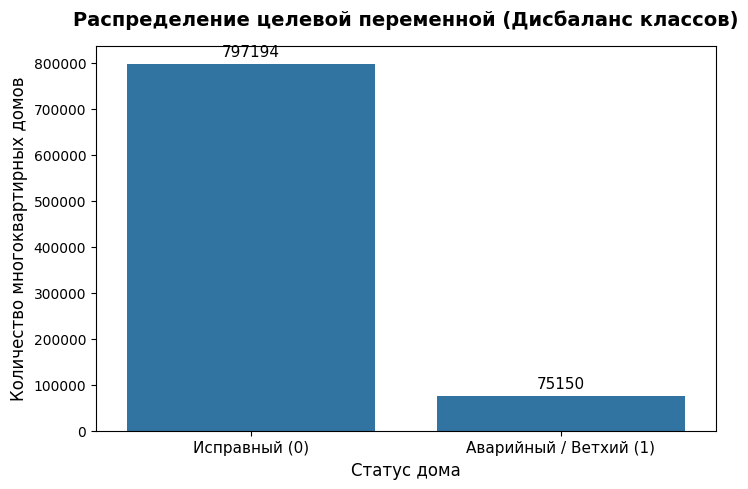

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x='Target')

plt.title('Распределение целевой переменной (Дисбаланс классов)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Статус дома', fontsize=12)
plt.ylabel('Количество многоквартирных домов', fontsize=12)

plt.xticks(ticks=[0, 1], labels=['Исправный (0)', 'Аварийный / Ветхий (1)'], fontsize=11)

for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'),
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points',
                fontsize=11)

plt.show()

Вывод по графику №1 (Дисбаланс классов):
Визуальный анализ распределения целевой переменной Target демонстрирует экстремальный дисбаланс (Class Imbalance). Объекты, официально признанные аварийными/ветхими, составляют абсолютное меньшинство генеральной совокупности. С точки зрения машинного обучения это означает риск того, что алгоритм будет склонен предсказывать мажоритарный класс (исправные дома). Для решения этой проблемы на этапе обучения модели потребуется применение механизма балансировки весов (class weights).

**График №2**: Возраст инфраструктуры

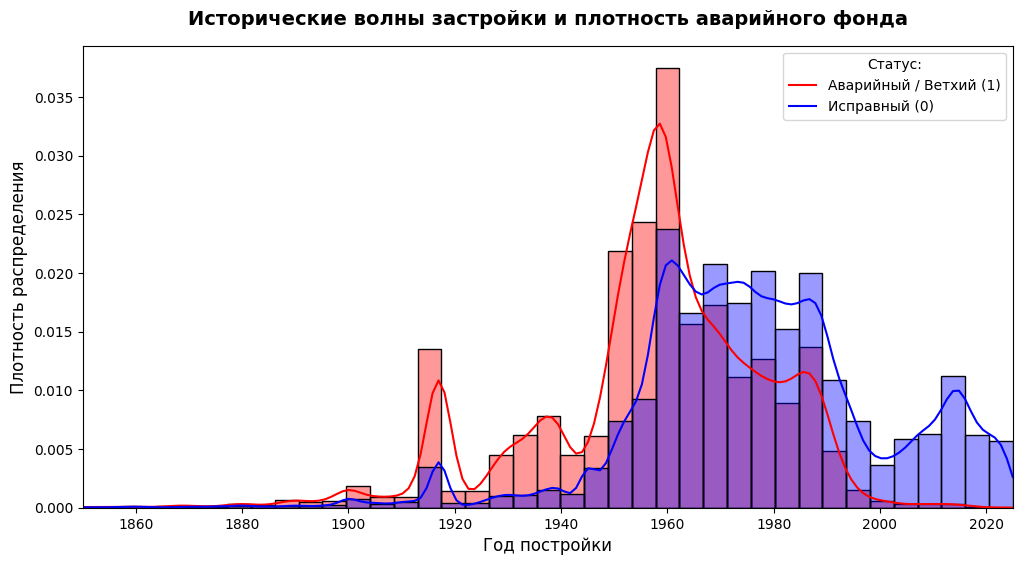

In [ ]:
plt.figure(figsize=(12, 6))

sns.histplot(data=df, x='building_year', hue='Target',
             kde=True, bins=50, stat='density', common_norm=False,
             palette={0: 'blue', 1: 'red'}, alpha=0.4)

plt.title('Исторические волны застройки и плотность аварийного фонда', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Год постройки', fontsize=12)
plt.ylabel('Плотность распределения', fontsize=12)

plt.legend(title='Статус:', labels=['Аварийный / Ветхий (1)', 'Исправный (0)'])

plt.xlim(1850, 2025)

plt.show()

Вывод по графику №2 (Возраст инфраструктуры):
Гистограмма распределения жилищного фонда по годам постройки с разделением на классы аварийности подтверждает, что пик ветхого жилья смещен в сторону зданий, возведенных в первой половине XX века.

**График №3**: Институциональный срез



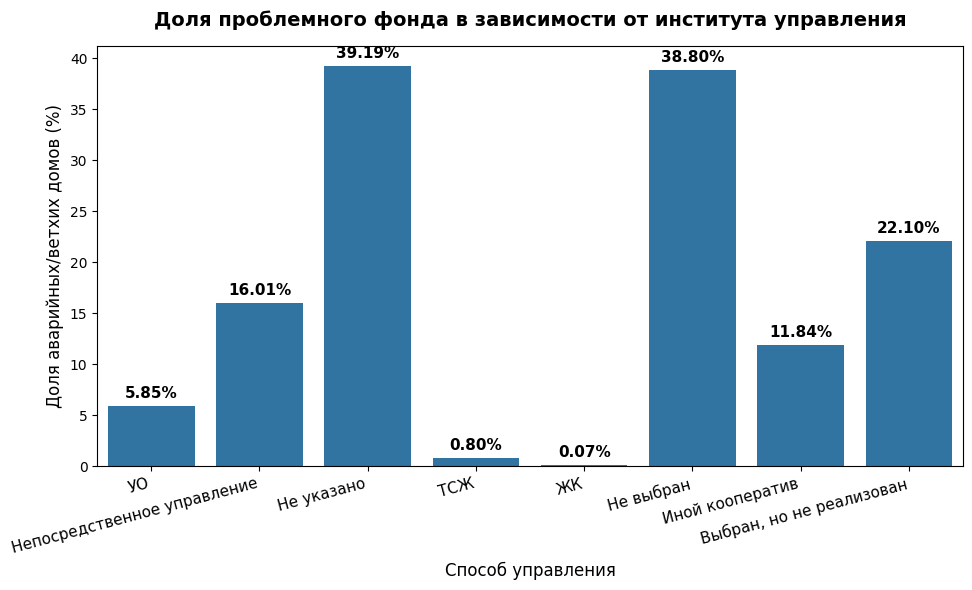

In [ ]:
plt.figure(figsize=(10, 6))

df_plot = df.copy()
df_plot['Target_percent'] = df_plot['Target'] * 100

ax = sns.barplot(data=df_plot, x='house_manegement_type', y='Target_percent',
                 errorbar=None)

plt.title('Доля проблемного фонда в зависимости от института управления', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Cпособ управления', fontsize=12)
plt.ylabel('Доля аварийных/ветхих домов (%)', fontsize=12)

plt.xticks(rotation=15, ha='right', fontsize=11)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

Вывод по графику №3: Гистограмма иллюстрирует долю деградировавшего жилья в разрезе юридических форм управления. Отчетливо видна, что в сегменте домов, находящихся под управлением Товариществ собственников жилья (ТСЖ/ЖСК), доля аварийности крайне мала.

## Дизайн статистического исследования
В качестве базовой модели выбран алгоритм градиентного бустинга над деревьями решений — **CatBoost** (Categorical Boosting).

Его преимущества для данного исследования:
1. **Нативная обработка категорий**: CatBoost математически корректно работает со строковыми (текстовыми) признаками "под капотом", используя целевое кодирование (Target Encoding). Это позволяет модели находить сложные нелинейные связи между субъектом РФ, серией здания и его износом.
2. **Устойчивость к выбросам и неполным данным**: Древовидная архитектура бустинга робастна к нетипичным значениям (например, ошибкам ввода площади), которые неизбежно присутствуют в массивах государственной статистики.
3. **Встроенная компенсация дисбаланса**: Использование гиперпараметра auto_class_weights='Balanced' заставляет функцию потерь штрафовать модель пропорционально редкости аварийного класса, максимизируя способность алгоритма "отлавливать" проблемные объекты.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from catboost import CatBoostClassifier, Pool

features = cat_features + num_features + ['is_reconstructed', 'is_dormitory']
X = df[features]
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = CatBoostClassifier(
    iterations=500,
    cat_features=cat_features,
    auto_class_weights='Balanced', # Решает проблему редких аварийных домов
    random_seed=42,
    verbose=100
)

model.fit(X_train, y_train, eval_set=(X_test, y_test))

Learning rate set to 0.215909
0:	learn: 0.5431095	test: 0.5415412	best: 0.5415412 (0)	total: 1.53s	remaining: 12m 46s
100:	learn: 0.2629577	test: 0.2515220	best: 0.2515220 (100)	total: 1m 54s	remaining: 7m 30s
200:	learn: 0.2535486	test: 0.2466078	best: 0.2466078 (200)	total: 3m 57s	remaining: 5m 53s
300:	learn: 0.2474929	test: 0.2442861	best: 0.2442861 (300)	total: 6m 6s	remaining: 4m 2s
400:	learn: 0.2426557	test: 0.2431112	best: 0.2430624 (393)	total: 8m 15s	remaining: 2m 2s
499:	learn: 0.2385284	test: 0.2426154	best: 0.2425875 (466)	total: 10m 19s	remaining: 0us

bestTest = 0.2425875093
bestIteration = 466

Shrink model to first 467 iterations.


CatBoostClassifier(auto_class_weights='Balanced', cat_features=['region_name', 'municipality_name', 'internal_walls_type', 'house_manegement_type', 'plan_series', 'house_type'], iterations=500, random_seed=42, verbose=100)

## Метрики оценки качества
Учитывая дисбаланс классов, стандартная метрика **Accuracy** (доля правильных ответов) является нерепрезентативной. Оценка качества алгоритма будет производиться на основе метрик **Precision** (точность), **Recall** (полнота), а также метрики **F1-score** и матрицы ошибок (**Confusion Matrix**). Для интерпретации социологических результатов будет применен анализ важности признаков (**Feature Importances**).

In [ ]:
preds = model.predict(X_test)
print(classification_report(y_test, preds))

              precision    recall  f1-score   support

           0       0.99      0.89      0.94    159439
           1       0.44      0.91      0.60     15030

    accuracy                           0.89    174469
   macro avg       0.72      0.90      0.77    174469
weighted avg       0.94      0.89      0.91    174469



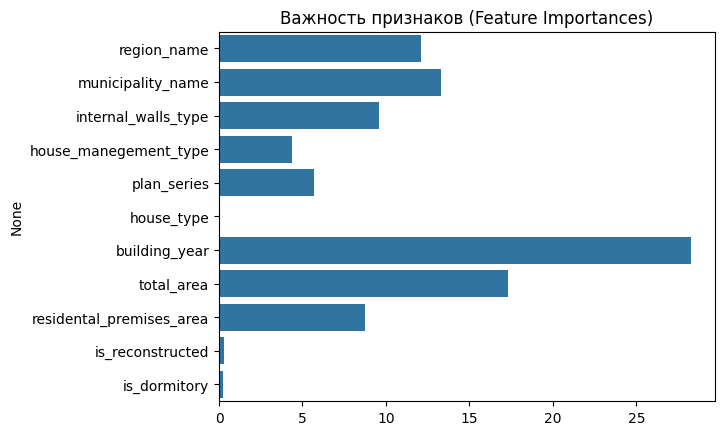

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

feature_importances = model.get_feature_importance()
sns.barplot(x=feature_importances, y=X.columns)
plt.title("Важность признаков (Feature Importances)")
plt.show()

### Вывод по Feature Importances:
1. Физические признаки
- Абсолютным лидером по силе предсказания ожидаемо стал **building_year** (Год постройки). Это подтверждает адекватность модели: законы физики и естественный износ материалов выступают первичным фактором риска. В связке с ним работают структурные характеристики: **total_area** (Общая площадь) и **internal_walls_type** (Материал стен). Высокая значимость площади объясняется тем, что основу аварийного фонда исторически составляют малоэтажные дома небольшой площади (например, двухэтажные деревянные бараки), в то время как крупные массивы поздней советской застройки деградируют медленнее.
2. Социально-пространственное неравенство
- Наибольший интерес представляет то, что пространственно-географические признаки — **municipality_name** (Муниципалитет) и **region_name** (Регион) — заняли 2-е и 3-е места среди всех факторов (не считая площади), в совокупности формируя колоссальный вес в принятии решения моделью.
Это доказывает выдвинутую гипотезу: статус «аварийного дома» — это социально-бюрократический конструкт. При одинаковом возрасте, площади и материале стен вероятность признания дома аварийным кардинально различается в зависимости от субъекта РФ и конкретного города. Это прямое отражение бюджетной обеспеченности: богатые муниципалитеты имеют средства на расселение и быстрее "навешивают" статус аварийности на старый фонд, тогда как в депрессивных регионах процесс бюрократически тормозится.
3. Роль институтов управления
- Институциональный признак **house_manegement_type** (Способ управления) вошел в ядро значимых факторов. Хотя его глобальный вес уступает возрасту и географии, его влияние остается статистически существенным. Алгоритм учитывает юридическую форму управления (например, защитный эффект ТСЖ по сравнению с муниципальными УК) при оценке риска деградации, что подтверждает важность прав коллективной собственности.
4. Специфика бинарных признаков
- Сконструированные бинарные признаки **is_reconstructed** (Факт реконструкции) и **is_dormitory** (Статус общежития) показали низкую глобальную важность. С методологической точки зрения машинного обучения это легко объяснимо: доля общежитий и реконструированных домов в генеральной совокупности (950 тыс. зданий) ничтожно мала. Алгоритм редко использует эти признаки для разбиения всей выборки. Однако их низкая глобальная важность не отменяет их высокой локальной значимости: для конкретного здания сам факт наличия статуса "общежитие" может выступать критическим триггером разрушения, что требует дальнейшего изучения

## Вывод
Таким образом, первоначальная исследовательская гипотеза подтвердилась: статус аварийности дома не является случайной, а алгоритмически выводим из набора объективных характеристик здания и институциональной среды.